# Electron Holography of a Material Needle

Active maintainer reconstruction and independently identified scientific comparisons.

## 1. Problem

Recover a finite-bandwidth **complex transmission ratio** from a real electron
hologram of an Fe needle with YOx inclusions and a separately recorded vacuum
reference. Carrier separation, finite aperture, weak local modulation and
reference distortions make this a wave-reconstruction inverse problem.

Save `output/reconstruction.npz`, key `reconstruction`, shape **(1,512,512)**,
complex64/complex128, batch, row, column. Values are dimensionless amplitude ratios
with principal argument in radians. The negative-sideband sign, common aperture
and vacuum correction fix the phase convention; no global phase alignment,
rescaling, crop or magnitude-only conversion is permitted. The selected method
is HoloSpy v0.3's Fourier wave stage. The associated material article is Migunov
et al., J. Appl. Phys. 117, 134301 (2015), DOI 10.1063/1.4916609; this notebook does
**not** claim its full multi-condition charge-density or mean-inner-potential
analysis. Neither the original reconstruction nor the fresh result is actual
wave truth.

## 2. Data

Data and software are HoloSpy v0.3, exact remotely verified commit
`fe4a0dae1e34e40215e9b20e5d836c321c2b5e07`, archive
https://doi.org/10.5281/zenodo.11099344, repository
https://github.com/hyperspy/holospy . Original files are
`holospy/data/01_holo_Vbp_130V_0V_bin2_crop.hdf5` (object) and
`00_ref_Vbp_130V_0V_bin2_crop.hdf5` (independent vacuum). Metadata explicitly
names the vacuum observation, Vadim Migunov as data author and Andrew London
as specimen preparer. The images are real, already binned/cropped experimental
products from a FEI Titan G2 60-300 HOLO at ER-C; 300 keV, 10 s, 130 V biprism,
5 degree tilt. HDF5-to-NPZ conversion preserves every int64 value and adds only
batch. No new crop/resampling/generation occurs. The archive declares CC-BY4.0
for its deposit; extracted source has separate GPL3-or-later notices, preserved
in full in the validation license record. The paper's full charge-density
analysis is beyond these two exposures.

`data/raw_data.npz` contains the original repository's already binned/cropped, real acquired intensity images, repackaged without numerical modification. Load with `allow_pickle=False`. Both keys are available at acquisition time; the vacuum image is calibration, not a target reconstruction.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| hologram | (1, 512, 512) | int64 | Object hologram intensity, detector counts; axes (batch, y, x). |
| vacuum | (1, 512, 512) | int64 | Separately recorded vacuum hologram intensity, detector counts; axes (batch, y, x). |

### Acquisition metadata

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Sample | Fe needle with YOx nanoparticle inclusions | dimensionless label | Material specimen; YOx indicates yttrium oxide without specified stoichiometry. |
| Instrument | FEI Titan G2 60-300 HOLO at ER-C | dimensionless label | Transmission electron microscope. |
| Beam energy | 300 | keV | Electron kinetic energy. |
| Exposure | 10 | s | Exposure for each image. |
| Biprism voltage | 130 | V | Interference acquisition setting. |
| Stage tilt | 5 | degree | Recorded specimen-stage tilt. |
| Pixel size d | 0.9197516441345215 | nm/pixel | Same square sample-plane spacing in both images. |
| x origin | 0 | nm | Physical x coordinate of column zero. |
| y origin | 183.9503288269043 | nm | Physical y coordinate of row zero. |
| Axis order | y increases with row, x increases with column | dimensionless convention | Retain supplied image orientation. |
| Dimensions Ny,Nx | 512,512 | pixel | No additional cropping or resampling. |
| Observed carrier ky,kx | 122,454 | DFT bin | Peak in the unshifted vacuum DFT; kx=454 is equivalent to -58. |
| Intensity calibration | gain-normalized detector counts | count | No absolute electron-count conversion is provided. |
| Noise model | not independently calibrated | dimensionless description | Retain measured noise; do not assume a supplied Gaussian variance. |
| Boundary convention | periodic DFT extension | dimensionless convention | Fourier filtering uses the complete supplied images. |

The sample's mean inner potential, thickness and charge density are not supplied or required for wave reconstruction. The table reports the binned/cropped images' calibrated axes rather than the original camera frame's pixel spacing.



In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'data/raw_data.npz').exists()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.preprocessing import load_observations
from src.solvers import reconstruct, estimate_carrier
from src.physics_model import sideband_wave
from src.visualization import observation_figure, comparison_figure
import importlib.util
spec = importlib.util.spec_from_file_location('independent_judge', ROOT / 'evaluation/judge.py')
judge = importlib.util.module_from_spec(spec); spec.loader.exec_module(judge)
data = load_observations(ROOT / 'data/raw_data.npz')
print({key: (value.shape, str(value.dtype)) for key, value in data.items()})

with np.load(ROOT/'data/raw_data.npz',allow_pickle=False) as visible:
    print('Visible acquisition arrays (batch first on disk):')
    for key in visible.files: print(key,visible[key].shape,str(visible[key].dtype))


{'hologram': ((1, 512, 512), 'float64'), 'vacuum': ((1, 512, 512), 'float64')}
Visible acquisition arrays (batch first on disk):
hologram (1, 512, 512) int64
vacuum (1, 512, 512) int64


## 3. Physics

For row/column indices (y, x), carrier bins (k_y, k_x), object wave O and reference R,

```math
I_o=|O+R e^{2\pi i(k_y y/N_y+k_x x/N_x)}|^2+\eta_o.
```

I is in counts, O and R in sqrt(count). The vacuum exposure replaces O by V.
The negative carrier cross terms are O*conj(R) and V*conj(R); selecting the
opposite band conjugates the recovered phase. Ny=Nx=512; d=0.9197516441345215
nm/pixel, physical x=d*x, physical y=183.9503288269043+d*y nm.

Define unnormalized negative-exponential forward DFT F and size-normalized
inverse F_inverse. Unshifted radial frequencies r=hypot(fftfreq(Ny,d),
fftfreq(Nx,d)) are in inverse nm. For positive radius a and smoothness b,

```math
A(r;a,b)=\tfrac12\{1-\tanh[(|r|-a)/(0.5b)]\},\quad
w_j=N_yN_xF^{-1}[A\,\operatorname{roll}(F(I_j)/(N_yN_x),k)],
\qquad q=w_o/w_v.
```

j labels object/vacuum and k is a positive (row, column) roll. The full-frame DFT
is periodic; no fftshift/crop/resize is used. Filtering produces count-valued
cross terms; their ratio q is dimensionless. Filtering then division is not
generally filtering the physical ratio. A common reference and adequate
carrier separation are assumptions. The finite aperture limits recoverable
bandwidth and reference instability/weak modulation can bias the result.
No potential, specimen thickness or charge density follows from q alone.

## 4. Method

Estimate carrier only from the visible vacuum: normalized DFT times central
stop 1-A(r;.05*maxr,1e-6 inverse_nm), magnitude argmax over rows 0..255 and
all columns. The original unshifted carrier is (122,454), equivalent to (122,-58).
Set rho to half the nearest Fourier-corner distance, 67.54257916307313 bins;
delta_f=mean(1/(Ny*d),1/(Nx*d)). Use radius a=rho*deltaf and smoothness
b=.05rho*deltaf. Apply the same positive roll and aperture to each exposure.

Compute the two count-valued waves and divide object by vacuum. If any vacuum
magnitude is <=float64_epsilon*maximum magnitude, raise an error; do not add
epsilon to the denominator. The real data have no numerical zeros. The inverse
is closed form: no initialization guess, objective, iterations, proximal
updates, training, learning rate or convergence rule is needed. No unwrapping,
phase alignment, masking, crop or amplitude renormalization follows division.

Actively preserve three scientific groups: original reproduced selected result,
fresh selected half-distance aperture, and fresh weak-object comparison with
2/3 radius and its own 5 percent edge. Also show the fresh uncorrected object
wave phase. The alternative bandwidth is not the submission. Both complex
relative L2 to the independent original reference and the public-data relation
||q*w_v-w_o||/||w_o|| must be <=1e-5. This nonzero tolerance was frozen from
original float32/double sensitivity 9.561154009425683e-7. It measures numerical
reproducibility and sideband consistency, not independently known material
properties. Original radial-grid/carrier/wave fixtures and analytic phase-sign,
DC rejection, aperture and vacuum self-calibration checks provide distinct
validation evidence.

## 5. Results

Every fresh reconstruction and comparison here is computed from the loaded real
observations using local src modules. Independent original-code outputs are
labeled references, never physical truth. Previously packaged snapshots are
kept byte-frozen; this execution's runtime and evidence are captured privately.
Display normalization affects figure contrast only, not quantitative arrays.


### Measured object/vacuum and their spectra

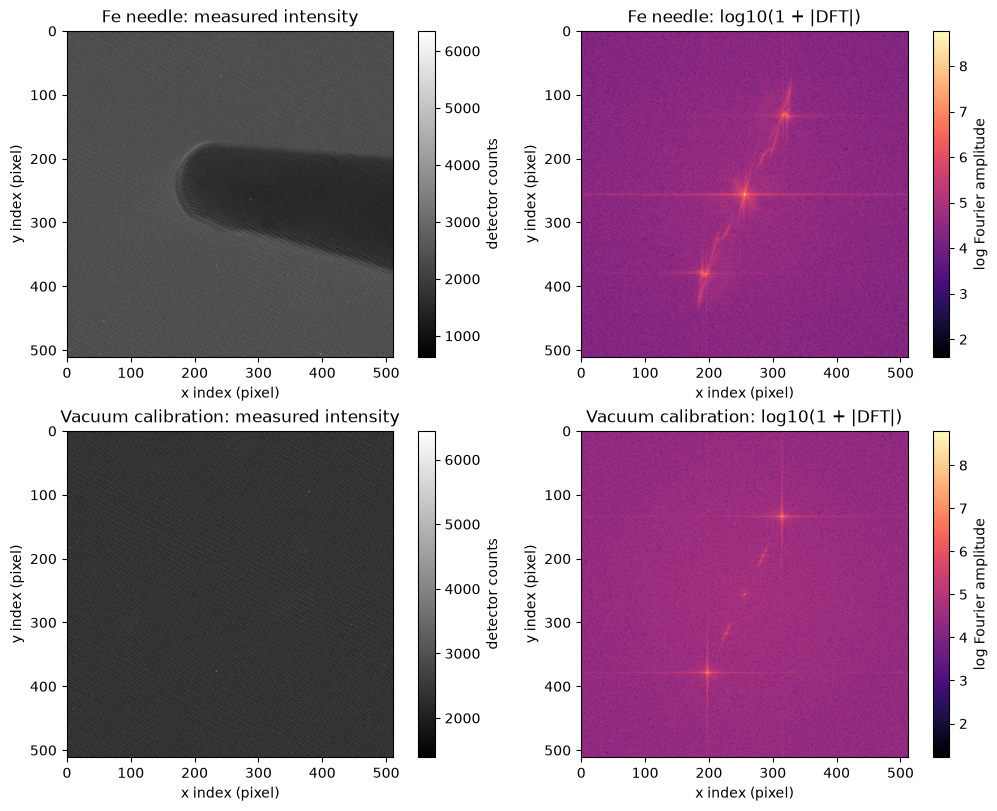

In [2]:
fig = observation_figure(data['hologram'], data['vacuum'])
display(fig); plt.close(fig)

### Fresh selected reconstruction plus active uncorrected/smaller-aperture comparisons

In [3]:
start = time.perf_counter()
fresh = reconstruct(data['hologram'], data['vacuum'])
runtime = time.perf_counter() - start
position, radius = estimate_carrier(data['vacuum'][0])
print(f'Fresh cleaned reconstruction runtime: {runtime:.6f} s; carrier={position}; radius={radius:.12f} Fourier pixels')
(ROOT / 'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT / 'output/reconstruction.npz', reconstruction=fresh)
with np.load(ROOT / 'notebooks/reference_outputs/upstream_measurements.npz', allow_pickle=False) as f:
    upstream = f['reconstruction']
# Both comparison methods are freshly computed, not substituted reference arrays.
uncorrected = sideband_wave(data['hologram'][0], position, radius)
weak_object = sideband_wave(data['hologram'][0], position, radius * 2 / 3)
weak_vacuum = sideband_wave(data['vacuum'][0], position, radius * 2 / 3)
weak_aperture = weak_object / weak_vacuum
report = judge.evaluate(ROOT / 'output/reconstruction.npz')
print(json.dumps(report, indent=2))
assert report['status'] == 'pass'
(ROOT / 'output/judge_report.json').write_text(json.dumps(report, indent=2), encoding='utf8')

Fresh cleaned reconstruction runtime: 0.052908 s; carrier=(122, 454); radius=67.542579163073 Fourier pixels


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "relative_complex_l2": 8.696900921068617e-16,
    "sideband_relative_l2": 3.874332211118671e-16
  },
  "thresholds": {
    "relative_complex_l2": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "sideband_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-05
    }
  },
  "errors": []
}


371

### All scientific wave comparisons and three-method measured metric table

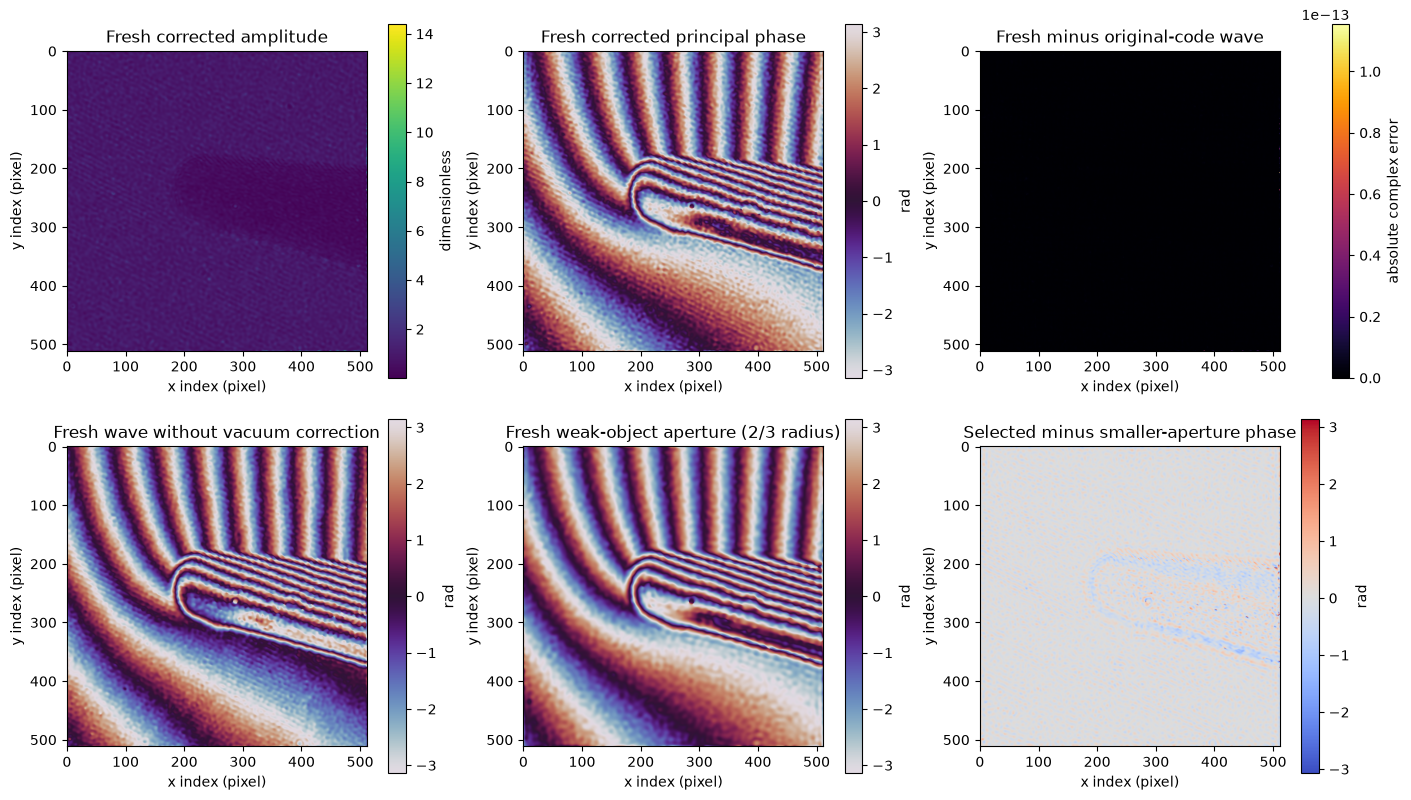

| Measurement | Relative complex L2 vs standard baseline | Observation-sideband relative L2 |
|---|---:|---:|
| Original-code reproduced bound observation | 0 | 6.60382582106e-16 |
| Fresh cleaned selected aperture | 8.69690092107e-16 | 3.87433221112e-16 |
| Fresh smaller-aperture comparison | 0.32790405647 | 0.248383570068 |


Full-precision fresh metrics: {'relative_complex_l2': 8.696900921068617e-16, 'sideband_relative_l2': 3.874332211118671e-16}


In [4]:
fig = comparison_figure(fresh, upstream, uncorrected, weak_aperture)
display(fig)
plt.close(fig)


rows = [('Original-code reproduced bound observation', upstream),
        ('Fresh cleaned selected aperture', fresh),
        ('Fresh smaller-aperture comparison', weak_aperture[None])]
text = '| Measurement | Relative complex L2 vs standard baseline | Observation-sideband relative L2 |\n|---|---:|---:|\n'
for label, value in rows:
    text += f'| {label} | {judge.relative_l2(value, upstream):.12g} | {judge.observation_consistency(value, ROOT / "data/raw_data.npz"):.12g} |\n'
display(Markdown(text))
print('Full-precision fresh metrics:', report['metrics'])

## 6. Conclusion

The fresh selected-aperture ratio agrees with the independent original wave
at relative complex L2 approximately 8.70e-16, with sideband consistency
approximately 3.87e-16, far below the prespecified 1e-5 limits. The measured
original/fresh/weak-bandwidth table and amplitude/phase panels preserve the
scientific distinction between vacuum correction and bandwidth selection.
The smaller aperture differs substantially (relative L2 about 0.3279), showing
that arbitrary smoothing is not an interchangeable evaluated output.

The finite carrier aperture, phase wrapping, low modulation ratios and reference
stability limit interpretation. Experimental phase structure remains; no mask
removes hard regions. Neither numerical agreement nor a tiny sideband residual
establishes independently measured true wave, potential, thickness or charge
density. Only the declared two-exposure Fourier wave stage is reproduced,
not the associated article's complete charge-density analysis.

Source provenance, independent original-run evidence, tests, precise parameter conventions and preserved copyright/license records: `test/validation.md`; executable mathematical and interface detail: `plan/approach.md` and `plan/design.md`.